# Week 1. Sampling and the score

This notebook accompanies Chapters 1 and 2 of the notes. It is not an exercise sheet. It runs from top to
bottom, and each section illustrates numerically a statement made in the lectures. At the end of each
section a few suggestions invite you to change parameters and see what happens.

1. The curse of dimensionality, for rejection sampling and for kernel density estimation.
2. The unadjusted Langevin algorithm (ULA) and its bias.
3. The score, its blindness to mixture weights, and denoising score matching.

Everything runs on a laptop CPU in about a minute.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from scipy.special import gammaln, logsumexp
from scipy.spatial.distance import cdist

rng = np.random.default_rng(0)
torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. The curse of dimensionality

### Rejection sampling from the ball via the cube

To sample uniformly from the unit ball $\mathcal B_2^n$, propose uniformly from the cube $[-1,1]^n$ and accept the
proposals that land in the ball. The acceptance probability is the volume ratio
$$
  \frac{|\mathcal B_2^n|}{2^n}=\frac{\pi^{n/2}}{2^n\,\Gamma(\frac n2+1)} .
$$
We compare this formula with a Monte Carlo estimate, and plot it on a logarithmic scale against $2^{-n}$.

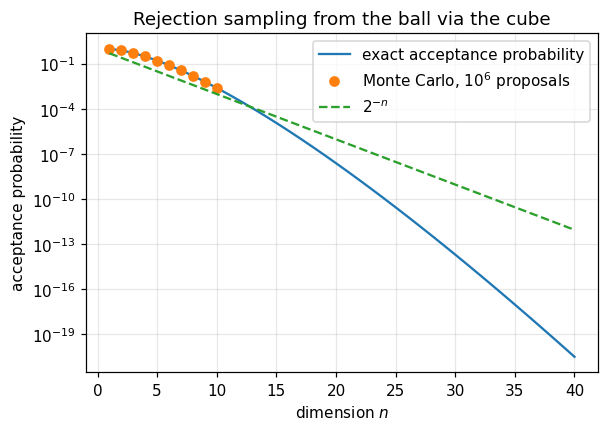

n = 13: acceptance 1.11e-04, 2^-n = 1.22e-04
n = 40: acceptance 3.28e-21, i.e. about 3.1e+20 proposals per sample


In [2]:
ns = np.arange(1, 41)
log_acc = 0.5 * ns * np.log(np.pi) - gammaln(ns / 2 + 1) - ns * np.log(2)

mc_ns = np.arange(1, 11)
mc = [np.mean(np.sum(rng.uniform(-1, 1, size=(10**6, n))**2, axis=1) <= 1) for n in mc_ns]

plt.figure(figsize=(6, 4))
plt.semilogy(ns, np.exp(log_acc), label="exact acceptance probability")
plt.semilogy(mc_ns, mc, "o", label="Monte Carlo, $10^6$ proposals")
plt.semilogy(ns, 2.0**(-ns), "--", label="$2^{-n}$")
plt.xlabel("dimension $n$"); plt.ylabel("acceptance probability"); plt.legend()
plt.title("Rejection sampling from the ball via the cube")
plt.show()
print(f"n = 13: acceptance {np.exp(log_acc[12]):.2e}, 2^-n = {2.0**-13:.2e}")
print(f"n = 40: acceptance {np.exp(log_acc[39]):.2e}, i.e. about {np.exp(-log_acc[39]):.1e} proposals per sample")

The acceptance probability decays faster than any exponential, and drops below $2^{-n}$ from $n=13$ on. The
reason is concentration of measure. A uniform point of the cube has $|X|^2\approx n/3$, so it almost never
lands in the ball.

### Kernel density estimation

In Chapter 1 we bounded the error of a kernel density estimator by a bias term and a variance
term. The variance is governed by $Nh^n$, roughly the number of data points in a window of size $h$. Here the
data are $N=20\,000$ samples of $\gamma_n=\mathcal N(0,I_n)$, the kernel is Gaussian with the usual bandwidth
$h\propto N^{-1/(n+4)}$, and we measure the relative error $|\hat f(x)/f(x)-1|$ at typical points $x\sim\gamma_n$.

n =  1   bandwidth h = 0.15   median relative error =    0.013   fraction of data within distance 1 = 5.3e-01
n =  2   bandwidth h = 0.19   median relative error =    0.028   fraction of data within distance 1 = 2.1e-01
n =  4   bandwidth h = 0.28   median relative error =    0.102   fraction of data within distance 1 = 2.8e-02
n =  8   bandwidth h = 0.41   median relative error =    0.347   fraction of data within distance 1 = 1.4e-04
n = 12   bandwidth h = 0.50   median relative error =    0.590   fraction of data within distance 1 = 2.5e-07
n = 16   bandwidth h = 0.57   median relative error =    0.749   fraction of data within distance 1 = 0.0e+00
n = 24   bandwidth h = 0.66   median relative error =    0.917   fraction of data within distance 1 = 0.0e+00
n = 32   bandwidth h = 0.72   median relative error =    0.987   fraction of data within distance 1 = 0.0e+00


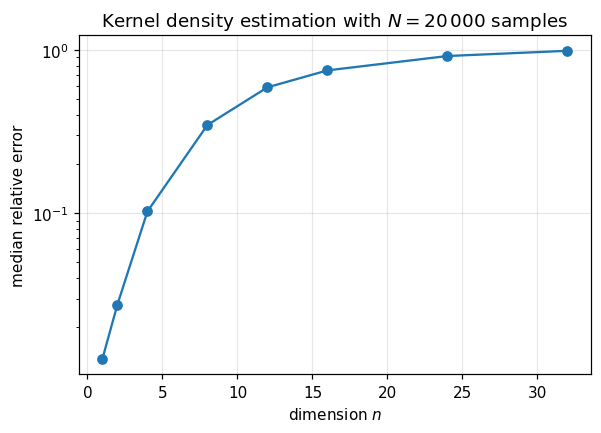

In [3]:
def kde_relative_error(n, N=20_000, M=200):
    data = rng.standard_normal((N, n))
    test = rng.standard_normal((M, n))
    h = (4 / (n + 2)) ** (1 / (n + 4)) * N ** (-1 / (n + 4))      # Silverman's rule
    d2 = cdist(test, data, "sqeuclidean")
    log_fhat = logsumexp(-d2 / (2 * h**2), axis=1) - np.log(N) - 0.5 * n * np.log(2 * np.pi * h**2)
    log_f = -0.5 * (test**2).sum(1) - 0.5 * n * np.log(2 * np.pi)
    within_one = np.mean(d2 < 1.0)                                   # fraction of data within distance 1
    return np.median(np.abs(np.exp(log_fhat - log_f) - 1)), h, within_one

dims = [1, 2, 4, 8, 12, 16, 24, 32]
res = [kde_relative_error(n) for n in dims]
for n, (err, h, w) in zip(dims, res):
    print(f"n = {n:2d}   bandwidth h = {h:.2f}   median relative error = {err:8.3f}   "
          f"fraction of data within distance 1 = {w:.1e}")

plt.figure(figsize=(6, 4))
plt.semilogy(dims, [r[0] for r in res], "o-")
plt.xlabel("dimension $n$"); plt.ylabel("median relative error")
plt.title("Kernel density estimation with $N=20\\,000$ samples")
plt.show()

With the same number of samples, the estimate is accurate in low dimension and useless in moderate
dimension. Around a typical point there are simply no data points, so the estimator has to use a huge
bandwidth, and its bias explodes. This is the curse of dimensionality of Chapter 1.

*Things to try.* Increase $N$ by a factor of $10$ and see how little the error improves for $n=16$. Replace the
bandwidth by a fixed value $h=0.3$ and watch the variance term take over.

## 2. The unadjusted Langevin algorithm

For a target $\mu\propto e^{-U}$, ULA iterates
$$
  X_{k+1}=X_k-h\nabla U(X_k)+\sqrt{2h}\,\xi_k,\qquad\xi_k\sim\mathcal N(0,I_n).
$$
For the Gaussian target $U(x)=\frac\alpha2|x|^2$ everything is explicit. The chain is linear,
$X_{k+1}=(1-\alpha h)X_k+\sqrt{2h}\,\xi_k$, and its stationary law is $\mathcal N(0,v_h I_n)$ with
$$
  v_h=\frac{2h}{1-(1-\alpha h)^2}=\frac{1}{\alpha(1-\alpha h/2)} ,
$$
which exceeds the target variance $1/\alpha$ by a factor $1+O(\alpha h)$. We check this in dimension $n=50$.

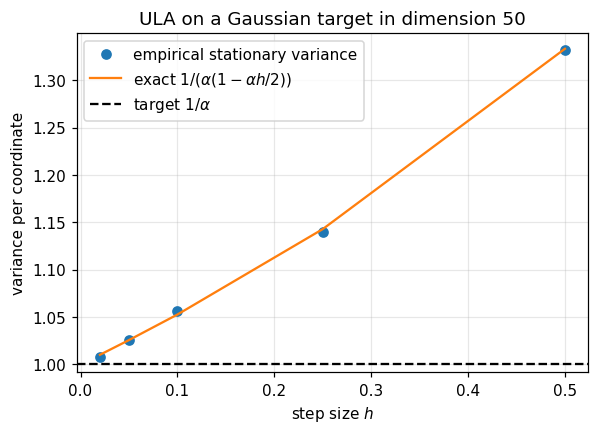

In [4]:
n, alpha, M = 50, 1.0, 4000
hs = [0.5, 0.25, 0.1, 0.05, 0.02]
emp, exact = [], []
for h in hs:
    x = 5.0 * np.ones((M, n))                     # start far from equilibrium
    for _ in range(int(20 / h)):                   # run up to time 20
        x = x - h * alpha * x + np.sqrt(2 * h) * rng.standard_normal((M, n))
    emp.append(x.var())
    exact.append(1 / (alpha * (1 - alpha * h / 2)))

plt.figure(figsize=(6, 4))
plt.plot(hs, emp, "o", label="empirical stationary variance")
plt.plot(hs, exact, "-", label=r"exact $1/(\alpha(1-\alpha h/2))$")
plt.axhline(1 / alpha, ls="--", c="k", label=r"target $1/\alpha$")
plt.xlabel("step size $h$"); plt.ylabel("variance per coordinate"); plt.legend()
plt.title("ULA on a Gaussian target in dimension 50")
plt.show()

The bias does not disappear with more iterations, only with a smaller step. This is the bias of ULA that
Chapter 3 quantifies in Wasserstein distance.

Langevin dynamics explores by local moves. On a multimodal target it can stay in one mode for a very long
time. Here the target is the mixture $0.8\,\mathcal N(-a e_1,s^2I_n)+0.2\,\mathcal N(ae_1,s^2I_n)$ in dimension
$n=20$, and we use the exact score. The particles start from $\mathcal N(0,I_n)$.

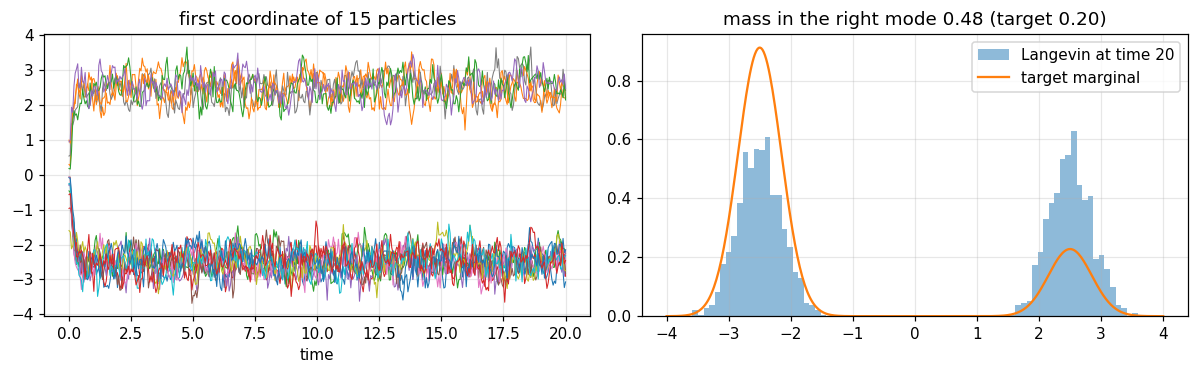

In [5]:
def mixture_score(x, a, s2, w=0.8, shrink=1.0):
    # score of w N(-shrink*a e1, s2 I) + (1-w) N(shrink*a e1, s2 I), x of shape (M, n)
    m = np.zeros(x.shape[1]); m[0] = shrink * a
    dl, dr = x + m, x - m
    log_l = np.log(w) - 0.5 * (dl**2).sum(1) / s2
    log_r = np.log(1 - w) - 0.5 * (dr**2).sum(1) / s2
    r_l = 1 / (1 + np.exp(np.clip(log_r - log_l, -50, 50)))
    return -(r_l[:, None] * dl + (1 - r_l)[:, None] * dr) / s2

n, a, s, h = 20, 2.5, 0.35, 1e-3
x = rng.standard_normal((2000, n))
traj = [x[:15, 0].copy()]
for k in range(int(20 / h)):
    x = x + h * mixture_score(x, a, s**2) + np.sqrt(2 * h) * rng.standard_normal(x.shape)
    if k % 50 == 0:
        traj.append(x[:15, 0].copy())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(np.linspace(0, 20, len(traj)), np.array(traj), lw=0.7)
ax[0].set_xlabel("time"); ax[0].set_title("first coordinate of 15 particles")
ax[1].hist(x[:, 0], bins=80, density=True, alpha=0.5, label="Langevin at time 20")
z = np.linspace(-4, 4, 400)
g = lambda m: np.exp(-0.5 * (z - m)**2 / s**2) / np.sqrt(2 * np.pi * s**2)
ax[1].plot(z, 0.8 * g(-a) + 0.2 * g(a), label="target marginal")
ax[1].legend(); ax[1].set_title(f"mass in the right mode {np.mean(x[:, 0] > 0):.2f} (target 0.20)")
plt.tight_layout(); plt.show()

No particle crosses between the modes, so the proportions are inherited from the initialisation and the
weights $0.8$ and $0.2$ are never learned. Week 2 explains this quantitatively, and Week 3 shows how diffusion
models avoid the problem.

## 3. The score and denoising score matching

### The score is blind to the weights

The score $\nabla\log\mu$ does not depend on the normalising constant of $\mu$, which is what makes it useful.
For a mixture of well-separated components, however, it also hardly depends on the weights. Away from the
region between the modes, the score of each mixture is the score of the nearest component.

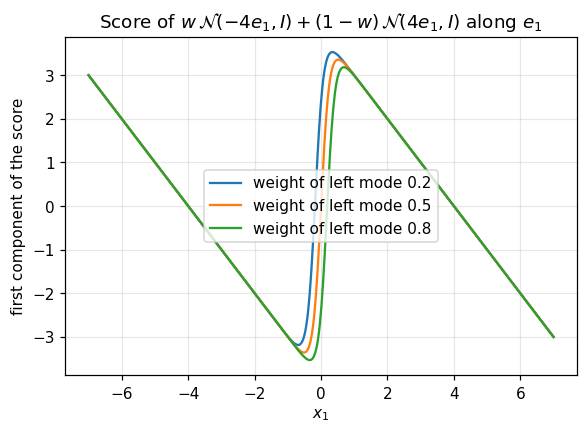

In [6]:
xs = np.linspace(-7, 7, 600)
pts = np.zeros((len(xs), 2)); pts[:, 0] = xs
plt.figure(figsize=(6, 4))
for w in [0.2, 0.5, 0.8]:
    plt.plot(xs, mixture_score(pts, a=4.0, s2=1.0, w=w)[:, 0], label=f"weight of left mode {w}")
plt.xlabel("$x_1$"); plt.ylabel("first component of the score")
plt.title(r"Score of $w\,\mathcal{N}(-4e_1,I)+(1-w)\,\mathcal{N}(4e_1,I)$ along $e_1$")
plt.legend(); plt.show()

The three curves differ only near the origin, where the mixture has almost no mass. So a score estimated
from data in the usual $L^2(\mu)$ sense carries almost no information about the weights, as we saw
in Chapter 2. Diffusion models get around this by estimating the scores of noised versions of $\mu$, in which the
modes overlap.

### Denoising score matching

Let $X\sim\mu$, $Z\sim\mathcal N(0,I)$ independent, and $Y=X+\sigma Z\sim\nu$. Denoising score matching minimises
$$
  \mathcal L_{\mathrm{DSM}}(s)=\mathbb E\Bigl|s(Y)+\frac{Z}{\sigma}\Bigr|^2,
$$
which only needs samples of $\mu$. Chapter 2 shows that
$\mathcal L_{\mathrm{DSM}}(s)=\mathbb E|s(Y)-\nabla\log\nu(Y)|^2+C$ with a constant $C$ independent of $s$. So minimising
it learns the score of the noised law $\nu$. We train a small neural network on a mixture of four Gaussians.
We work in the plane, but only so that the vector fields can be drawn. Nothing in the method depends on
the dimension.

In [7]:
centers = 3.0 * np.array([[1, 1], [1, -1], [-1, 1], [-1, -1]], dtype=float)
weights = np.array([0.4, 0.3, 0.2, 0.1]); s_comp, sigma = 0.5, 0.6

def sample_mu(N):
    idx = rng.choice(4, size=N, p=weights)
    return centers[idx] + s_comp * rng.standard_normal((N, 2))

def score_nu(y):
    # exact score of nu = mu * N(0, sigma^2 I), a mixture with component variance s_comp^2 + sigma^2
    v = s_comp**2 + sigma**2
    d = y[:, None, :] - centers[None]                       # (N, 4, 2)
    logp = np.log(weights)[None] - 0.5 * (d**2).sum(-1) / v
    r = np.exp(logp - logsumexp(logp, axis=1, keepdims=True))
    return -(r[..., None] * d).sum(1) / v

net = nn.Sequential(nn.Linear(2, 128), nn.SiLU(), nn.Linear(128, 128), nn.SiLU(), nn.Linear(128, 2))
opt = torch.optim.Adam(net.parameters(), lr=2e-3)
losses = []
for step in range(4000):
    x = torch.tensor(sample_mu(512), dtype=torch.float32)
    z = torch.randn_like(x)
    loss = ((net(x + sigma * z) + z / sigma)**2).sum(1).mean()
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())

# Check the identity L_DSM(s) = E|s - grad log nu|^2 + C on fresh samples.
x = sample_mu(200_000); z = rng.standard_normal(x.shape); y = x + sigma * z
with torch.no_grad():
    s_hat = net(torch.tensor(y, dtype=torch.float32)).numpy()
s_true = score_nu(y)
L_hat = np.mean(((s_hat + z / sigma)**2).sum(1))
L_true = np.mean(((s_true + z / sigma)**2).sum(1))
excess = np.mean(((s_hat - s_true)**2).sum(1))
print(f"DSM loss of the network       {L_hat:.4f}")
print(f"DSM loss of the exact score   {L_true:.4f}   (the constant C is not zero)")
print(f"difference                    {L_hat - L_true:.4f}")
print(f"E|s_hat - grad log nu|^2      {excess:.4f}   (should match the difference)")

DSM loss of the network       2.3124
DSM loss of the exact score   2.2831   (the constant C is not zero)
difference                    0.0293
E|s_hat - grad log nu|^2      0.0287   (should match the difference)


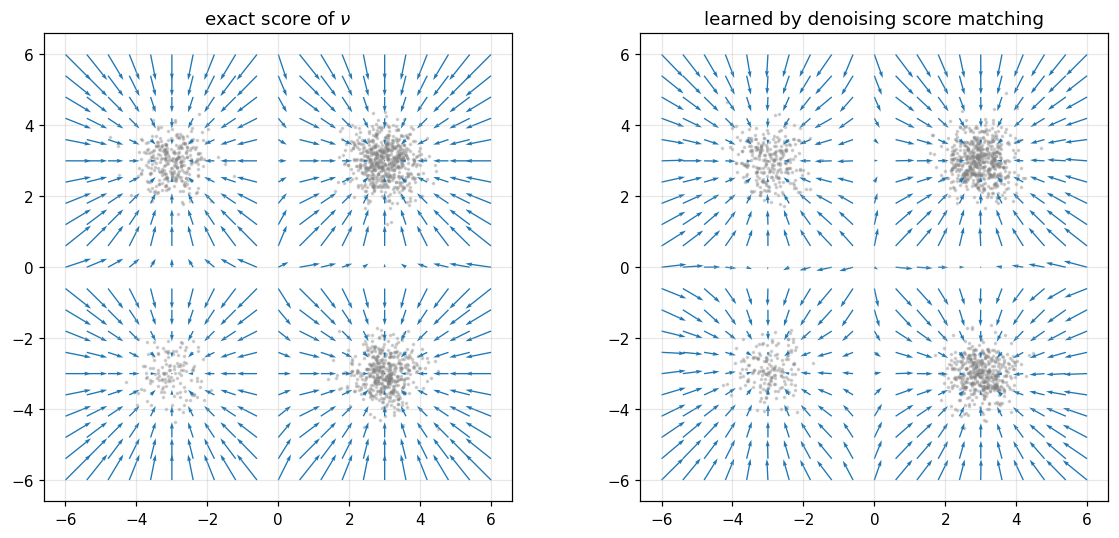

In [8]:
g1 = np.linspace(-6, 6, 21)
G = np.stack(np.meshgrid(g1, g1), -1).reshape(-1, 2)
with torch.no_grad():
    S_hat = net(torch.tensor(G, dtype=torch.float32)).numpy()
S_true = score_nu(G)
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a_, S, title in [(ax[0], S_true, r"exact score of $\nu$"), (ax[1], S_hat, "learned by denoising score matching")]:
    a_.scatter(*sample_mu(1500).T, s=2, alpha=0.3, c="gray")
    a_.quiver(G[:, 0], G[:, 1], S[:, 0], S[:, 1], color="tab:blue", angles="xy", scale=90)
    a_.set_title(title); a_.set_aspect("equal")
plt.tight_layout(); plt.show()

### Tweedie's formula

The learned score also gives a denoiser. By Tweedie's formula,
$\mathbb E[X\mid Y=y]=y+\sigma^2\nabla\log\nu(y)$. Applying it to noisy points moves each of them towards the
clean points that could have produced it. Points between two modes are moved to a compromise, since the
posterior mean averages over both.

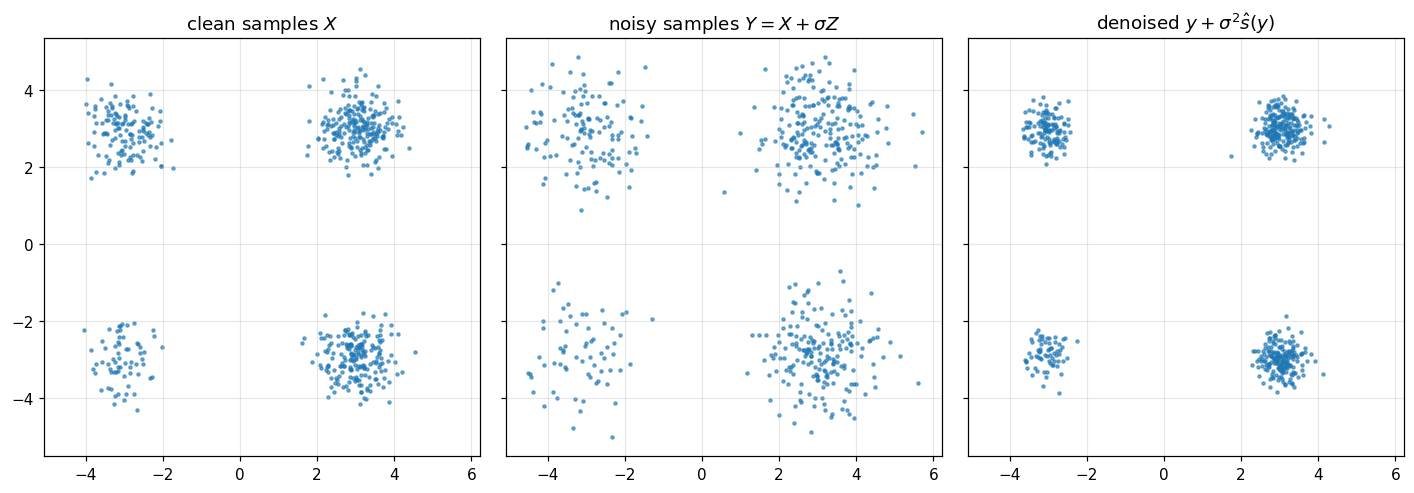

In [9]:
x = sample_mu(600); y = x + sigma * rng.standard_normal(x.shape)
with torch.no_grad():
    x_hat = y + sigma**2 * net(torch.tensor(y, dtype=torch.float32)).numpy()
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for a_, pts, title in [(ax[0], x, "clean samples $X$"), (ax[1], y, r"noisy samples $Y=X+\sigma Z$"),
                       (ax[2], x_hat, r"denoised $y+\sigma^2\hat s(y)$")]:
    a_.scatter(*pts.T, s=4, alpha=0.6); a_.set_title(title); a_.set_aspect("equal")
plt.tight_layout(); plt.show()

The denoised points are more concentrated than the clean ones. The posterior mean is the best guess in
$L^2$, not a sample, so it averages out the uncertainty that remains after observing $Y$.

*Things to try.* Increase $\sigma$ to $2$. The learned score becomes easier to learn and the modes merge in
$\nu$, so the score now does see the weights. Decrease $\sigma$ to $0.1$ and watch the training become noisy,
because the target $-Z/\sigma$ has variance $n/\sigma^2$. Balancing these two effects is exactly why diffusion models
use a whole range of noise levels.